# 🛠️ Vision AI 특강 정리: 환경 설정과 CLI 연결

> 핵심 한 줄: **내 PC는 명령만 내리고, 무거운 연산은 Colab GPU가 한다.** 이 특강의 진짜 주제는 모델이 아니라 **그 연결을 위한 환경 설정**이다.

| 항목 | 내용 |
|---|---|
| 실습 저장소 | [yblee110/vision-ai-notebook](https://github.com/yblee110/vision-ai-notebook) |
| 개발 환경 | GitHub Codespaces (devcontainer로 자동 세팅, Python 3.12) |
| 연결 도구 | Hugging Face CLI `hf` 0.36.0 · Google Colab CLI `colab` 0.6.0 |
| 원격 연산 | Colab GPU 런타임 (T4), 컴퓨팅 유닛(CU)으로 결제 |
| 실습 예제 | DeiT-tiny로 병·그릇·캔·컵·접시 분류 (연결을 확인하는 예제일 뿐) |

## 📌 목차

0. 내 소감: 막혔던 점과 깨달은 점
1. 한눈에 보기: 환경 3층 구조
2. 왜 환경을 이렇게 나누나
3. 1층: Codespaces 개발 환경 자동 세팅
4. 직접 해보니: Windows에서 재현한 결과
5. 2층: 인증 (Hugging Face, Google)
6. 3층: Colab 런타임 연결 (CLI 명령)
7. 연결 자동화: 셸 스크립트와 에이전트 스킬
8. GPU 고르기와 비용
9. 환경 트러블슈팅
10. 복습 체크리스트
- 부록 A. 실습 코드 흐름 요약
- 부록 B. 모델 실행 결과 (CPU 재현)

## 0. 내 소감: 막혔던 점과 깨달은 점

### 😵 막혔던 점: README(마크다운)가 제대로 안 보였다

- Codespaces(VS Code)에서 `README.md`를 열면 `#`, `|`, `**` 기호가 그대로 보여서 안내를 따라가기 힘들었다.
- 환경 설정 안내가 거의 다 README에 있어서 이게 막히면 진행 전체가 막힌다.

| 해결법 | 동작 |
|---|---|
| `Ctrl + Shift + V` | 현재 탭을 미리보기(렌더링)로 열기 |
| `Ctrl + K` 다음 `V` | 옆 창에 미리보기 열기. 원본과 나란히 보면서 명령을 복사하기 좋다 |
| `.md` 우클릭 → Open Preview | 마우스로 열기 |

### 💡 깨달은 점: 왜 CLI로 연결하나

> **내 컴퓨터 자원(GPU·메모리)이 부족한데 모델을 돌리고 싶을 때** 쓰는 것이다.

- 내 PC와 Codespaces(CPU 2코어·8GB)에는 GPU가 없다.
- `colab` CLI는 터미널 명령 몇 줄로 **Colab GPU를 빌려와서** 코드를 실행하고 결과만 가져온다.
- 명령어라서 반복 실행, 자동화, AI 에이전트 연결까지 된다.
- 그러려면 **CLI가 돌아가는 환경**부터 제대로 만들어야 한다. 그래서 이 특강의 절반이 환경 설정이다.

## 1. 한눈에 보기: 환경 3층 구조

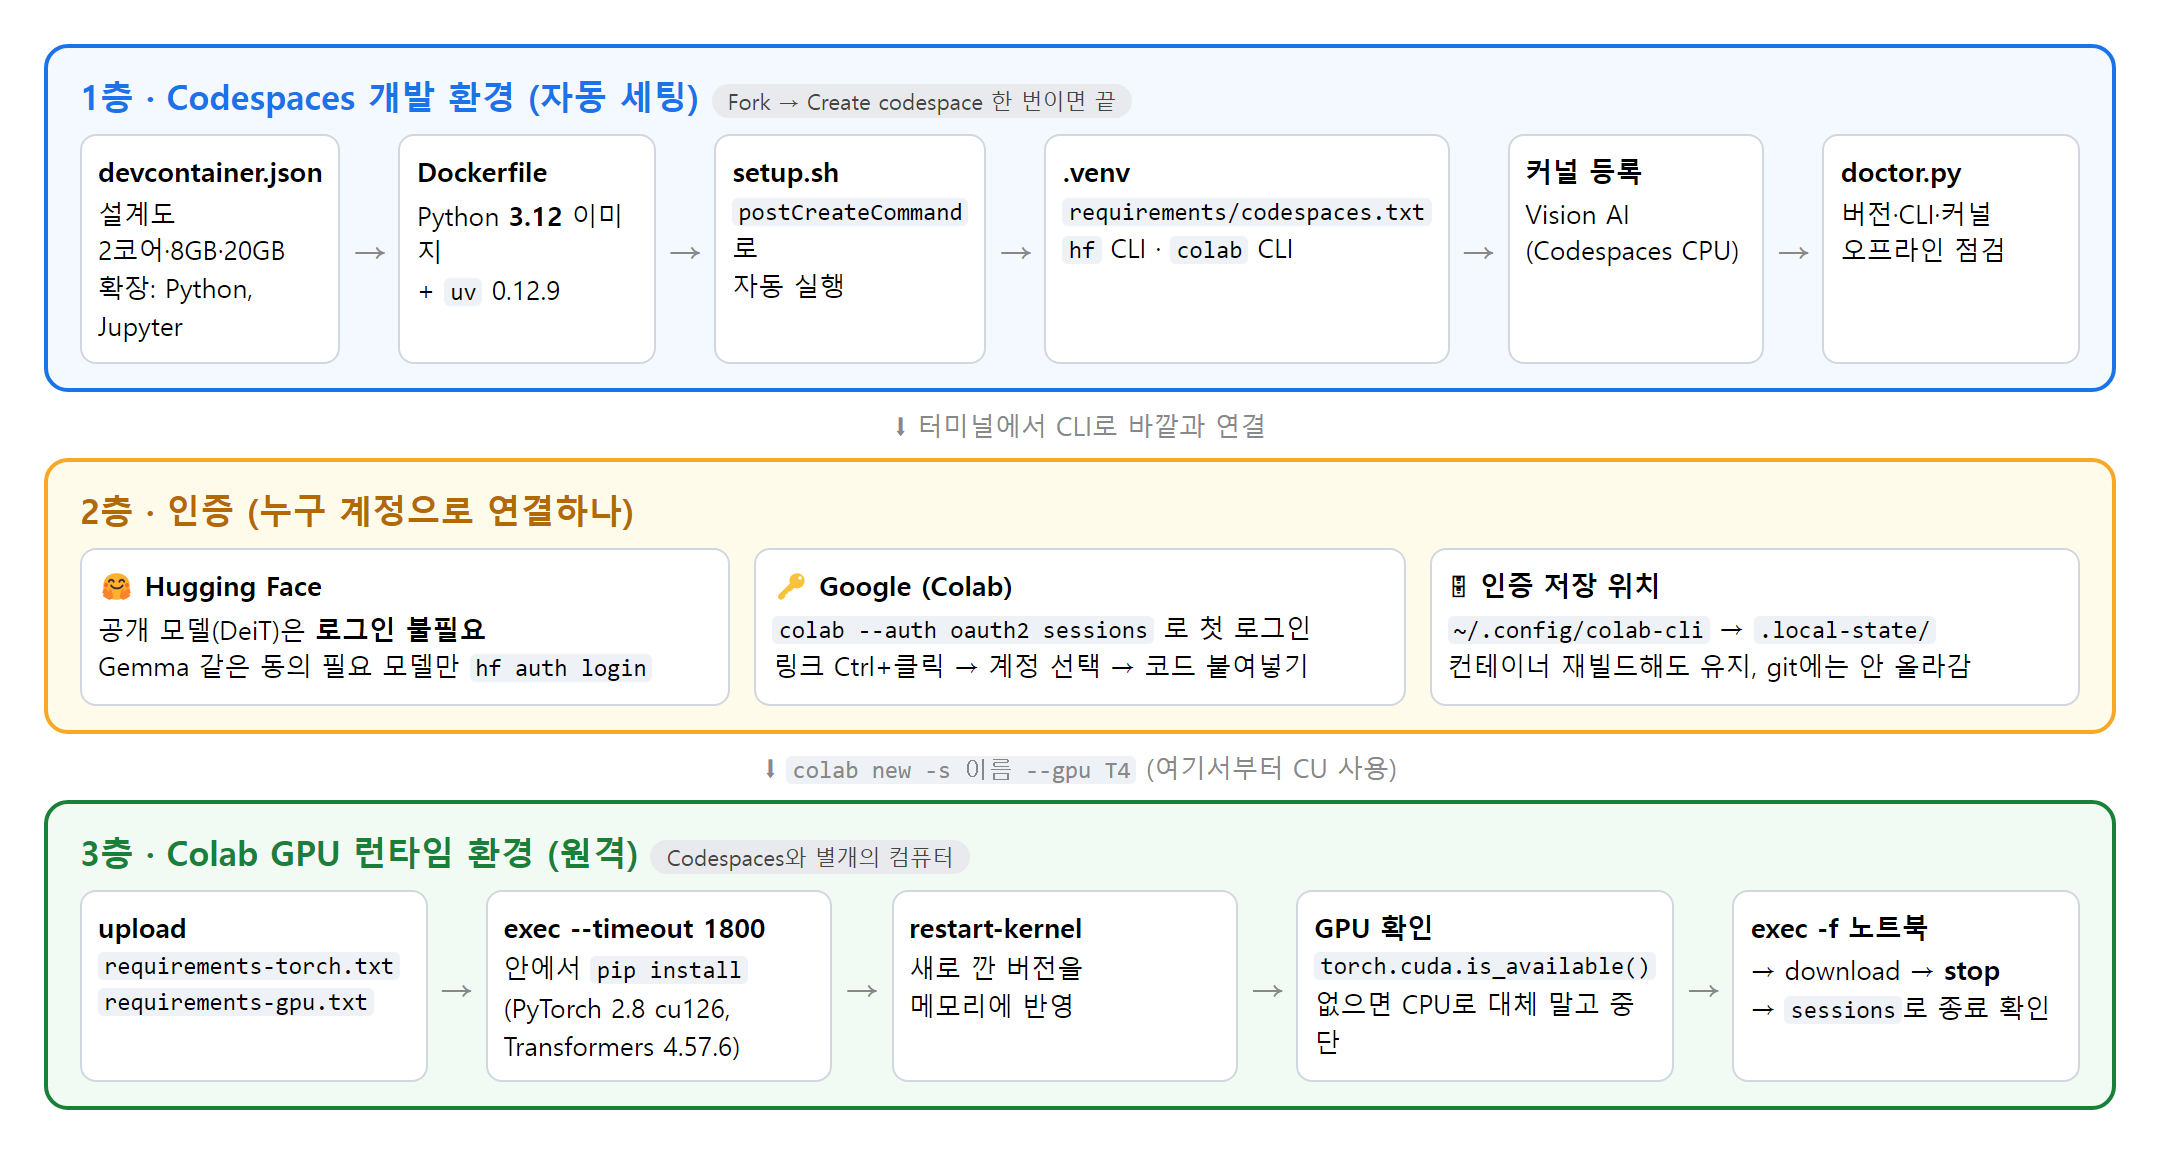

In [1]:
# 환경 3층 구조: Codespaces 자동 세팅 → 인증 → Colab 런타임
from IPython.display import Image
Image("images/env_layers.png")

| 층 | 어디서 | 무엇을 맞추나 | 핵심 명령·파일 |
|---|---|---|---|
| 1층 개발 환경 | Codespaces (리눅스, CPU) | Python 3.12, `.venv`, `hf`·`colab` CLI, 노트북 커널 | `devcontainer.json`, `setup.sh`, `doctor.py` |
| 2층 인증 | Codespaces 터미널 | 누구 계정으로 HF·Colab에 접속하나 | `colab --auth oauth2 sessions` |
| 3층 원격 런타임 | Colab GPU (T4) | PyTorch·Transformers 설치, GPU 확인 | `colab new`, `upload`, `exec`, `stop` |

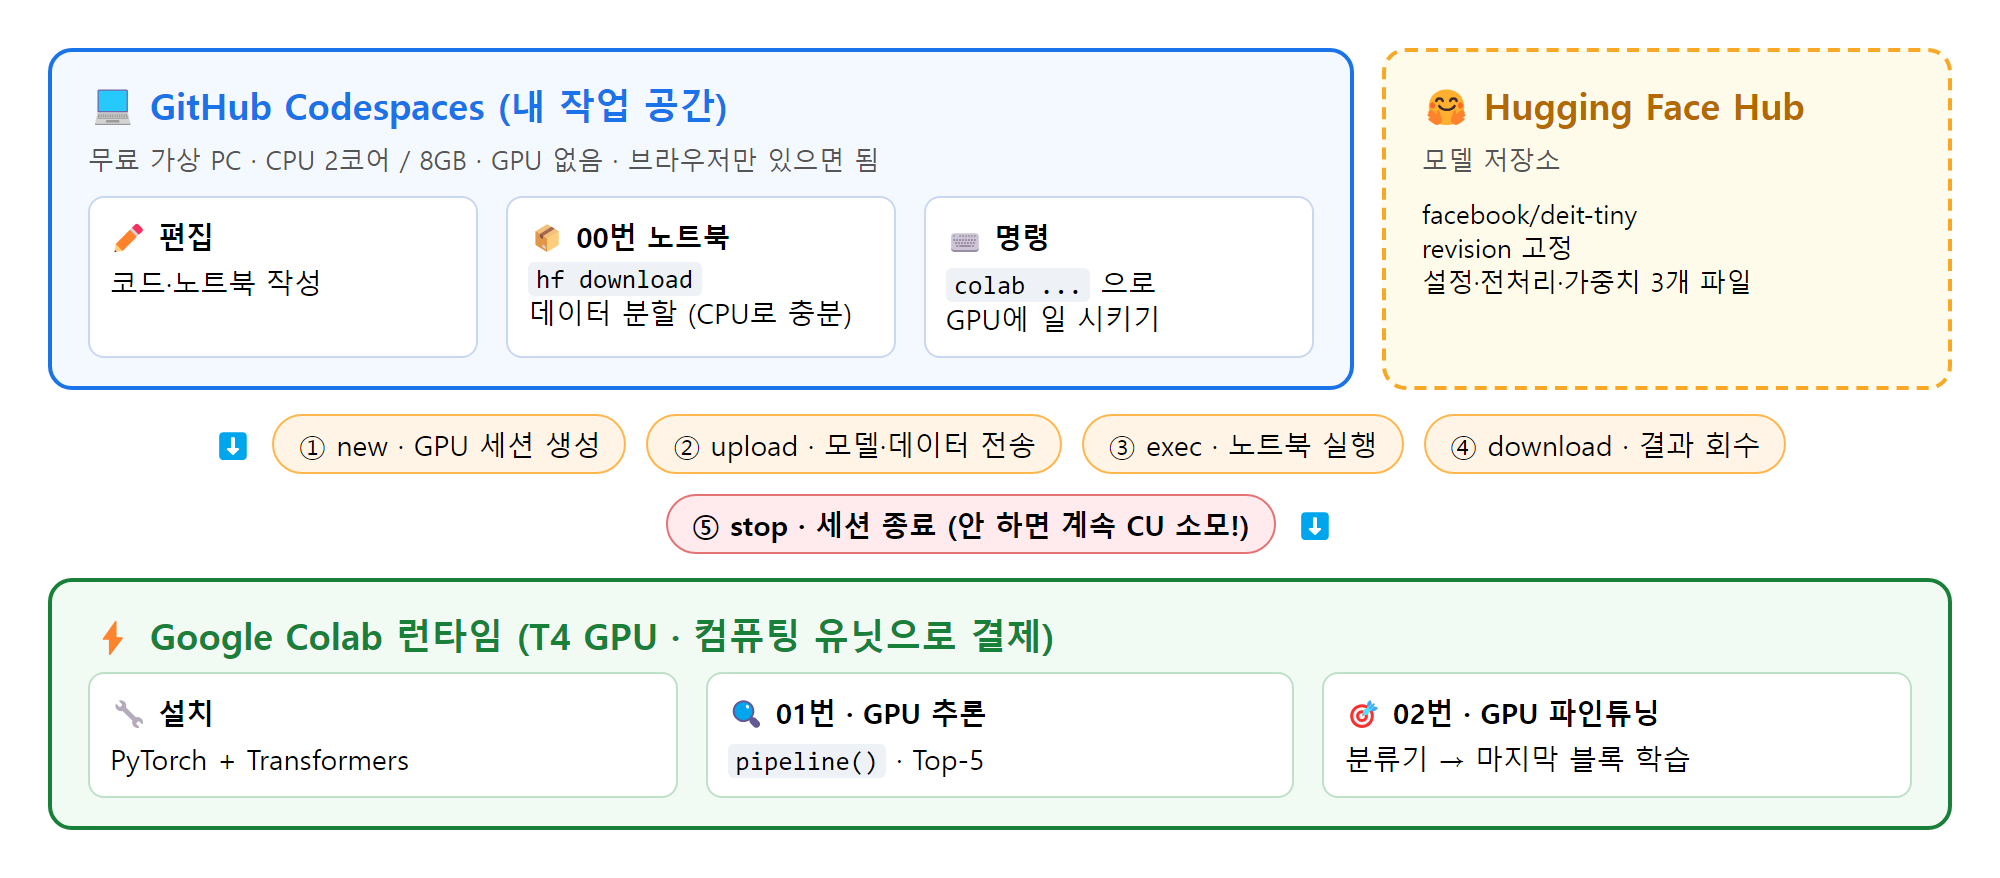

In [2]:
# 데이터와 명령의 흐름: Codespaces에서 명령하고 Colab GPU가 연산
from IPython.display import Image
Image("images/architecture.png")

## 2. 왜 환경을 이렇게 나누나

| 구분 | 내 PC | Codespaces | Colab GPU |
|---|---|---|---|
| 역할 | 브라우저만 있으면 됨 | 편집, 다운로드, CLI 명령 | 무거운 연산 (추론·학습) |
| 사양 | 사람마다 다름 (Windows/Mac) | 모두 같은 리눅스 + Python 3.12 | T4 GPU 등 |
| 비용 | 없음 | 무료 사용량 (강의 안내 기준 하루 4시간 정도) | 컴퓨팅 유닛(CU) |

- **Codespaces를 쓰는 이유:** 학생마다 OS가 달라도 **똑같은 환경**에서 시작한다. 강사님도 "윈도우라고 하면 머리가 아프다"고 했다. 아래 4장에서 실제로 Windows에서는 Colab CLI가 안 돌아가는 것을 확인했다.
- **Colab CLI를 쓰는 이유:** Colab 노트북(웹)과 **같은 런타임**을 쓰지만, 터미널 명령이라 반복·자동화·에이전트 연결이 된다.
- **비용이 안전한 이유:** Colab Pro는 매달 CU 100개를 준다. 다 쓰면 무료 정책으로 바뀐다. RunPod(자동 충전)나 GCP(사용량 과금)는 GPU를 끄지 않으면 계속 돈이 나간다. 강의 예시로 B200을 8시간 켜 두면 약 160만 원이다.

| 구분 | Colab 노트북 (웹) | Colab CLI (터미널) |
|---|---|---|
| 형태 | 웹 노트북, 구글 드라이브 연동 | VS Code 같은 편집기에서 파일 작성 |
| 반복 | 세션 재시작·셀 재실행을 사람이 직접 | 스크립트를 한 번 더 실행하면 끝 |
| 잘 맞는 일 | 탐색, 시각화 | 자동화, 작업 연결, 에이전트 연동 |
| 런타임 | T4, L4, A100, TPU | 노트북과 **같은 런타임** |

## 3. 1층: Codespaces 개발 환경 자동 세팅

### 3-1. 시작 순서

1. 수업 저장소에서 **Fork** → Owner를 내 계정으로 → **Create fork**
2. **내가 Fork한 저장소**에서 Code → Codespaces → **Create codespace on main** (머신은 2코어·8GB)
3. VS Code 화면이 떠도 설치가 계속될 수 있다. 터미널에 **준비 완료** 안내가 나올 때까지 기다린다.
4. 터미널에서 `source .venv/bin/activate` 다음 `python scripts/doctor.py`로 점검한다.
5. 00번 노트북을 열고 **커널 선택 → Jupyter 커널 → Vision AI (Codespaces CPU)**를 고른다.

> Codespace를 만들고 점검하는 동안에는 Google 로그인도, Colab GPU 할당도 일어나지 않는다. 돈이 드는 단계는 6장의 `colab new`부터다.

### 3-2. 자동 세팅을 만드는 파일들

| 파일 | 하는 일 | 핵심 설정 |
|---|---|---|
| `.devcontainer/devcontainer.json` | Codespace의 **설계도** | 사양, 자동 실행 명령, 환경 변수, VS Code 확장 |
| `.devcontainer/Dockerfile` | 기본 OS와 도구 | Python 3.12 이미지 + `uv` 0.12.9 |
| `scripts/setup.sh` | 생성 직후 **자동 실행**되는 설치 스크립트 | `.venv` 생성, 라이브러리 설치, 커널 등록, 점검 |
| `requirements/codespaces.txt` | Codespaces용 라이브러리 목록 (버전 고정) | `hf`·`colab` CLI 포함 11개 |
| `.vscode/settings.json` | 기본 Python 경로 | `.venv/bin/python` |
| `scripts/doctor.py` | 오프라인 환경 점검 | 버전·CLI·커널·인증 저장 위치 |

#### devcontainer.json 읽기

```json
{
  "build": { "dockerfile": "Dockerfile", "context": ".." },
  "hostRequirements": { "cpus": 2, "memory": "8gb", "storage": "20gb" },
  "postCreateCommand": "bash scripts/setup.sh",
  "remoteEnv": {
    "PATH": "${containerWorkspaceFolder}/.venv/bin:${containerEnv:PATH}",
    "VIRTUAL_ENV": "${containerWorkspaceFolder}/.venv",
    "MPLBACKEND": "Agg",
    "OMP_NUM_THREADS": "2"
  },
  "customizations": { "vscode": {
    "extensions": ["ms-python.python", "ms-toolsai.jupyter"],
    "settings": { "python.defaultInterpreterPath": "${workspaceFolder}/.venv/bin/python" }
  } }
}
```

| 설정 | 쉬운 설명 |
|---|---|
| `build.dockerfile` | 이 Dockerfile로 컨테이너를 만든다 |
| `hostRequirements` | 최소 2코어·8GB·20GB 머신을 요구한다 |
| `postCreateCommand` | 컨테이너가 처음 만들어진 직후 `setup.sh`를 **자동 실행**한다 |
| `remoteEnv.PATH` | `.venv/bin`을 맨 앞에 둔다. 그래서 `hf`, `colab`을 경로 없이 바로 쓸 수 있다 |
| `MPLBACKEND=Agg` | 화면 없는 서버에서도 그래프를 파일로 그릴 수 있게 한다 |
| `OMP_NUM_THREADS=2` | 2코어 머신에 맞게 연산 스레드를 제한한다 |
| `extensions` | Python·Jupyter 확장을 자동 설치한다 |
| `defaultInterpreterPath` | 노트북·터미널이 기본으로 `.venv`의 Python을 쓰게 한다 |

#### Dockerfile 읽기

```dockerfile
FROM ghcr.io/astral-sh/uv:0.12.9 AS uv
FROM mcr.microsoft.com/devcontainers/python:1-3.12-bookworm
COPY --from=uv /uv /uvx /usr/local/bin/
```

- 첫 줄: `uv` 실행 파일이 든 이미지를 잠깐 가져온다.
- 둘째 줄: 실제 기반은 **Python 3.12 + Debian(bookworm)** 리눅스 이미지다.
- 셋째 줄: 첫 이미지에서 `uv`만 복사해 넣는다. `uv`는 pip보다 훨씬 빠른 설치 도구다.

#### setup.sh 핵심 줄 읽기

```bash
uv venv --python 3.12 --allow-existing .venv                       # ① 가상환경 만들기
uv pip install --python .venv/bin/python -r requirements/codespaces.txt   # ② 라이브러리 설치
.venv/bin/python -m ipykernel install --prefix "$LAB_ROOT/.venv" \
  --name codespaces-vision-ai --display-name 'Vision AI (Codespaces CPU)'  # ③ 노트북 커널 등록
.venv/bin/python scripts/doctor.py --configure-state-only           # ④ 인증 저장 위치 연결
.venv/bin/python scripts/doctor.py                                  # ⑤ 전체 점검
```

1. 프로젝트 안에 Python 3.12 가상환경 `.venv`를 만든다. 이미 있으면 그대로 쓴다.
2. 목록에 적힌 **정확한 버전**으로 설치한다.
3. 노트북에서 고를 커널 이름을 `Vision AI (Codespaces CPU)`로 등록한다.
4. Colab 로그인 정보가 컨테이너를 다시 만들어도 남도록 저장 위치를 연결한다 (5장).
5. 점검 결과를 보여 준다. 이 과정에서 Google 로그인이나 Colab 자원 생성은 없다.

### 3-3. Codespaces에 설치되는 라이브러리

| 패키지 | 버전 | 하는 일 |
|---|---|---|
| `huggingface_hub[cli]` | 0.36.0 | `hf download` 명령 |
| `google-colab-cli` | 0.6.0 | `colab` 명령 |
| `jupyter-kernel-client` | 0.9.0 | Colab CLI 0.6.0이 원격 커널과 통신할 때 쓰는 부품. 버전이 맞아야 한다 |
| `numpy`, `Pillow`, `pyarrow` | 2.5.2, 12.3.0, 20.0.0 | 이미지 읽기, 데이터 분할 |
| `matplotlib` | 3.11.1 | 그래프 |
| `ipykernel`, `nbformat`, `nbclient` | 7.3.0, 5.10.4, 0.10.4 | 노트북 커널과 실행 |
| `pytest` | 9.1.1 | 수업 코드 검사 |

> **PyTorch는 여기 없다.** GPU용 PyTorch는 Codespaces가 아니라 Colab에 설치한다 (6장). 그래서 Codespaces에서 01·02 노트북을 Run All 하면 `import torch`부터 에러가 난다.

### 3-4. 환경 점검: doctor.py

```bash
source .venv/bin/activate
python scripts/doctor.py
python -c "import sys; print(sys.executable)"
```

| 점검 항목 | 확인 내용 |
|---|---|
| `python` | 3.12인지, `.venv` 안의 Python인지 |
| 패키지 11개 | 목록의 버전과 정확히 같은지 |
| `colab executable` | `colab --help`가 실행되는지 |
| `Hugging Face executable` | `hf --help`가 실행되는지 |
| `Colab execution API` | `jupyter-kernel-client`가 CLI와 호환되는지 (연결은 안 함) |
| `notebook kernel` | 등록된 커널이 이 `.venv`를 가리키는지 |
| `credential persistence` | 로그인 정보 저장 위치가 연결됐는지 |

`doctor.py`는 **오프라인 점검**만 한다. 로그인, GPU 할당, 모델 다운로드는 하지 않는다.

### 3-5. 환경이 이상할 때

- `.venv`가 없거나 자동 설치가 실패했다 → 오류를 읽고 `bash scripts/setup.sh`를 다시 실행한다.
- `uv`가 없다거나 설정 파일을 고쳤다 → 작업을 저장한 뒤 명령 팔레트에서 **Codespaces: Rebuild Container**.
- `ModuleNotFoundError` → 셀에 설치 명령을 넣기 전에 **커널이 Vision AI (Codespaces CPU)인지** 먼저 확인한다.
- 커널 목록에 안 보인다 → 커널 선택 → **다른 커널 선택**에서 찾는다.

## 4. 직접 해보니: Windows에서 재현한 결과

수업 설정이 왜 이렇게 생겼는지 확인하려고 **내 Windows PC에서 같은 환경을 직접 만들어 봤다** (2026-10-03).

### ① Python 3.10에서는 Colab CLI가 설치되지 않는다

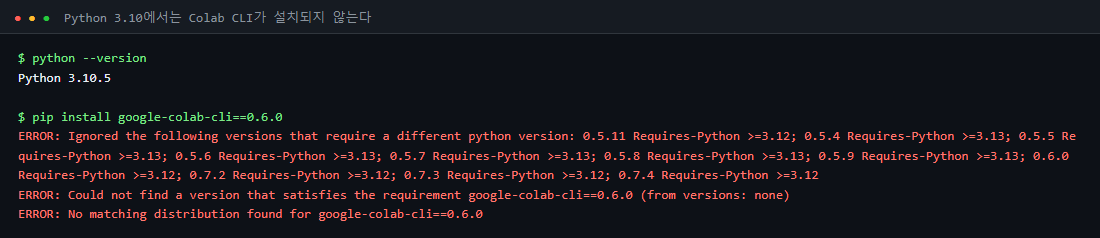

In [3]:
# Python 3.10에서 google-colab-cli 설치 실패
from IPython.display import Image
Image("images/env_01_python310_fail.png")

`google-colab-cli` 0.6.0은 **Python 3.12 이상**을 요구한다. 그래서 Dockerfile이 Python 3.12 이미지를 쓴다.

### ② setup.sh와 같은 방법으로 환경 만들기

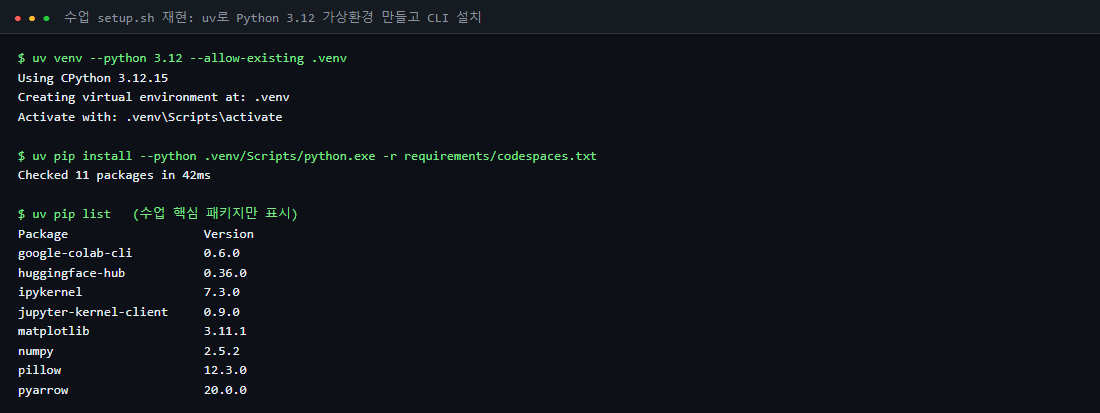

In [4]:
# uv로 Python 3.12 가상환경을 만들고 수업 패키지 설치
from IPython.display import Image
Image("images/env_02_uv_setup.png")

`uv`가 Python 3.12를 직접 내려받아 가상환경을 만들었고, 수업 목록의 11개 패키지가 정확한 버전으로 설치됐다.

### ③ doctor.py로 점검

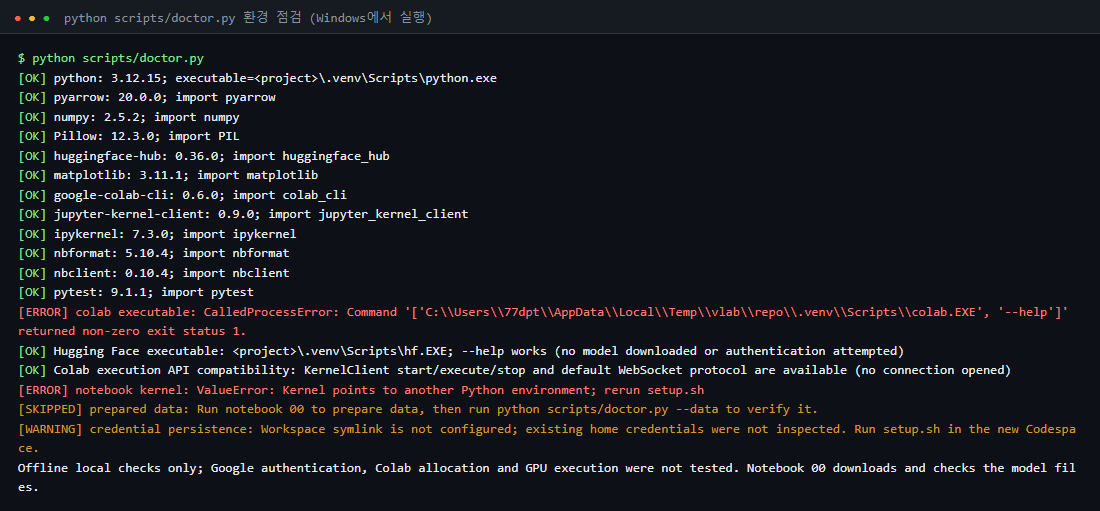

In [5]:
# doctor.py 점검 결과 (Windows)
from IPython.display import Image
Image("images/env_03_doctor.png")

- 패키지 11개와 `hf` CLI는 모두 **[OK]**.
- `colab executable`은 **[ERROR]**. 아래 ④에서 이유를 확인했다.
- `notebook kernel`도 **[ERROR]**. 점검 코드가 리눅스 경로(`.venv/bin/python`)를 기대하는데 Windows는 `.venv\Scripts\python.exe`라서 다르게 나온다.

### ④ Windows에서는 colab 명령 자체가 안 돈다

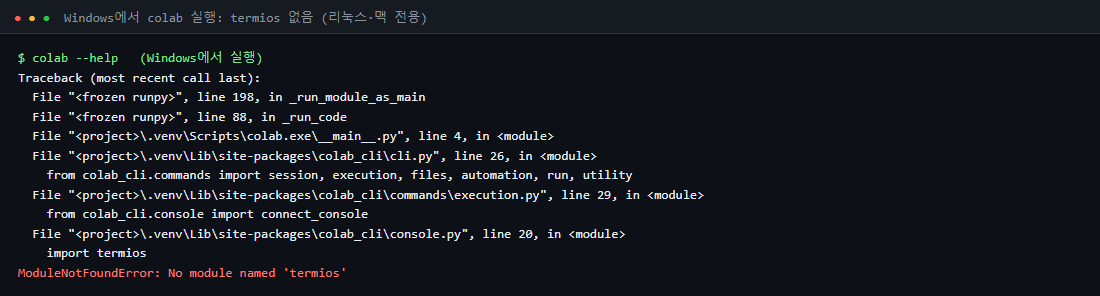

In [6]:
# Windows에서 colab --help 실행 시 termios 오류
from IPython.display import Image
Image("images/env_04_colab_windows.png")

`termios`는 **리눅스·맥에만 있는** 터미널 제어 모듈이다. Colab CLI는 공식적으로 Linux와 macOS만 지원한다.

> **결론:** 내 PC가 Windows라면 Colab CLI를 바로 쓸 수 없다. **Codespaces(리눅스, Python 3.12)를 쓰는 이유가 바로 이것**이다. 내 PC에서 쓰고 싶다면 WSL(리눅스)을 따로 설치해야 한다.

## 5. 2층: 인증 (누구 계정으로 연결하나)

### Hugging Face

- 이번 모델 `facebook/deit-tiny-patch16-224`는 공개 모델이라 **로그인이 필요 없다.**
- Gemma처럼 라이선스 동의가 필요한(gated) 모델은 `hf auth login`이 필요할 수 있다.
- 토큰은 노트북·커밋·업로드 파일에 절대 넣지 않는다.

### Google (Colab CLI)

```bash
colab --auth oauth2 sessions
```

1. 위 명령을 **터미널에서 직접** 실행한다. `colab login` 명령은 0.6.0에 없다.
2. 터미널에 나온 링크를 `Ctrl + 클릭`해서 브라우저로 연다.
3. 본인 Google 계정을 고르고 권한을 허용한다.
4. 받은 코드를 복사해 터미널에 붙여 넣는다.
5. `No active sessions` 같은 목록이 나오면 로그인 성공이다.

| 인증 방식 | 누가 쓰나 | 사용법 |
|---|---|---|
| `oauth2` | 학생 (기본값) | `colab --auth oauth2 ...` |
| `adc` | ADC(Google 기본 인증)를 이미 준비한 강사 | 모든 명령에 `--auth adc`를 **일관되게** 붙인다 |

### 로그인 정보는 어디에 저장되나

- `setup.sh`가 `~/.config/colab-cli`를 프로젝트의 `.local-state/colab-cli`로 연결한다 (권한 700).
- 그래서 **컨테이너를 다시 빌드해도 로그인이 유지**된다.
- `.local-state`는 `.gitignore`와 `.dockerignore`에 들어 있어서 **git에 올라가지 않는다.**

## 6. 3층: Colab 런타임 연결 (CLI 명령)

### 6-1. 핵심 명령어

| 명령 | 의미 |
|---|---|
| `colab --auth oauth2 sessions` | 로그인과 열린 세션 목록 확인 |
| `colab new -s 이름 --gpu T4` | 새 GPU 세션 생성. **여기서부터 CU 사용** |
| `colab status -s 이름` | 세션 상태 확인 |
| `colab upload -s 이름 로컬경로 원격경로` | 파일 올리기 |
| `colab exec -s 이름 --timeout 초` | 원격에서 Python 실행 (`-f 파일`로 노트북·스크립트 실행) |
| `colab restart-kernel -s 이름` | 원격 커널 재시작 |
| `colab download -s 이름 원격경로 로컬경로` | 결과 파일 받기 |
| `colab stop -s 이름` | **세션 종료** |
| `colab sessions` | 종료됐는지 확인 |

### 6-2. 세션을 열고 원격 환경 만들기

```bash
# 1) 세션 생성과 확인
colab new -s hf-vision-gpu --gpu T4
colab status -s hf-vision-gpu

# 2) 설치 목록 올리기
colab upload -s hf-vision-gpu hf_colab_gpu/requirements-torch.txt content/requirements-torch.txt
colab upload -s hf-vision-gpu hf_colab_gpu/requirements-gpu.txt   content/requirements-gpu.txt

# 3) 원격에서 pip 설치 (30분까지 기다림)
colab exec -s hf-vision-gpu --timeout 1800 <<'PY'
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-r','/content/requirements-torch.txt'], check=True)
subprocess.run([sys.executable,'-m','pip','install','-r','/content/requirements-gpu.txt'], check=True)
print('HF_GPU_LIBRARIES_READY')
PY

# 4) 새 버전 반영
colab restart-kernel -s hf-vision-gpu

# 5) GPU가 정말 붙었는지 확인
colab exec -s hf-vision-gpu --timeout 120 <<'PY'
import torch
assert torch.cuda.is_available(), 'GPU를 찾지 못했습니다.'
print('GPU:', torch.cuda.get_device_name(0))
PY
```

| 단계 | 왜 이렇게 하나 |
|---|---|
| `-s hf-vision-gpu` | 이름을 안 주면 `92c9d...` 같은 임의 이름이 붙어 관리가 어렵다 |
| `--gpu T4` | 안 주면 다른 가속기가 붙을 수 있다 |
| `colab install` 대신 `exec`와 `pip` | 0.6.0의 `install`은 대기시간이 약 60초라 큰 PyTorch 설치가 중간에 끊긴다 |
| `--timeout 1800` | 단위는 **초**. 1800초 = 30분. 출력 없이 오래 걸리는 작업이 끊기지 않게 넉넉히 준다 |
| `restart-kernel` | 설치 전에 메모리에 올라간 옛 버전과 섞이지 않게 한다 |
| `torch.cuda.is_available()` | GPU가 없으면 CPU로 몰래 돌리지 말고 **멈춘다** |
| `<<'PY' ... PY` | 셸의 here-document. 사이에 적은 Python 코드를 그대로 원격에 보낸다 |

**Colab에 설치하는 버전**

| 파일 | 내용 |
|---|---|
| `requirements-torch.txt` | CUDA 12.6용 공식 배포처에서 `torch==2.8.0`, `torchvision==0.23.0` |
| `requirements-gpu.txt` | `transformers==4.57.6`, `huggingface_hub==0.36.0`, `safetensors==0.8.0`, `numpy`, `Pillow`, `matplotlib` |

### 6-3. 원격 경로 규칙

```bash
# 업로드는 상위 폴더를 자동으로 만들지 않는다 → 먼저 exec로 폴더 만들기
colab exec -s hf-vision-gpu --timeout 120 <<'PY'
from pathlib import Path
Path('/content/vision-ai/data/prepared').mkdir(parents=True, exist_ok=True)
PY
colab upload -s hf-vision-gpu data/prepared/train.npz content/vision-ai/data/prepared/train.npz
```

- CLI의 파일 경로 `content/vision-ai/...` 는 Colab 안 Python에서 `/content/vision-ai/...` 이다. **앞의 `/` 유무만 다르다.**
- 모델·데이터는 노트북과 **따로 올려야** 한다. 노트북만 실행한다고 파일이 따라가지 않는다.
- `exec -f`는 **로컬 파일의 내용**을 보내서 실행한다. 그래서 원격 코드에서 `__file__`에 기대면 안 된다.

### 6-4. 실행, 회수, 종료

```bash
colab exec -s hf-vision-gpu -f hf_colab_gpu/notebooks/01_gpu_inference.ipynb  --timeout 1800
colab exec -s hf-vision-gpu -f hf_colab_gpu/notebooks/02_gpu_finetuning.ipynb --timeout 1800
colab download -s hf-vision-gpu content/vision-ai/hf_colab_gpu/results/gpu/report.json hf_colab_gpu/results/gpu/report.json
colab stop -s hf-vision-gpu
colab sessions
```

> ⚠️ **꼭 기억할 것**
>
> 1. 세션은 **자동으로 꺼지지 않는다.** `stop` 후 `sessions`로 비었는지 확인한다.
> 2. `--timeout`은 셀 대기시간이지 **자동 종료 시간이 아니다.**
> 3. CLI는 셀 오류가 나도 **뒤 셀을 계속 실행**한다. 명령이 끝났다고 성공이 아니다. `*_output.ipynb`에서 오류를 확인한다.
> 4. 오류가 났다고 새 세션을 계속 만들지 않는다. 기존 세션 상태부터 확인한다.
> 5. 끝나면 **Colab 세션 종료 + Codespace 중지** 둘 다 한다. 사용량이 따로 계산된다.

### 6-5. 💻 이 PC에서 환경 확인해 보기

아래 셀은 지금 노트북을 연 컴퓨터에 두 CLI가 있는지 확인한다. 설치나 로그인은 하지 않는다.

In [7]:
import platform, shutil, sys

print("OS     :", platform.system())
print("Python :", sys.version.split()[0], "(Colab CLI는 3.12 이상 필요)")
for tool in ("hf", "colab", "uv"):
    print(f"{tool:<6} :", shutil.which(tool) or "없음")
if platform.system() == "Windows":
    print("\n→ Windows에서는 colab CLI가 동작하지 않는다. Codespaces나 WSL(리눅스)에서 실행하자.")

OS     : Windows
Python : 3.10.5 (Colab CLI는 3.12 이상 필요)
hf     : 없음
colab  : 없음
uv     : 없음

→ Windows에서는 colab CLI가 동작하지 않는다. Codespaces나 WSL(리눅스)에서 실행하자.


In [8]:
# ⏱ --timeout은 초 단위: 몇 분 기다릴지 초로 바꿔 보기
for minutes in (2, 10, 30):
    print(f"{minutes:>3}분 → --timeout {minutes * 60}")

  2분 → --timeout 120
 10분 → --timeout 600
 30분 → --timeout 1800


## 7. 연결 자동화: 셸 스크립트와 에이전트 스킬

### 7-1. 명령 9개를 스크립트 하나로

`hf_colab_gpu/run_pipeline_colab.sh`는 6장의 명령들을 순서대로 묶은 셸 파일이다. `--dry-run`은 로그인·GPU 없이 **계획만** 보여 준다.

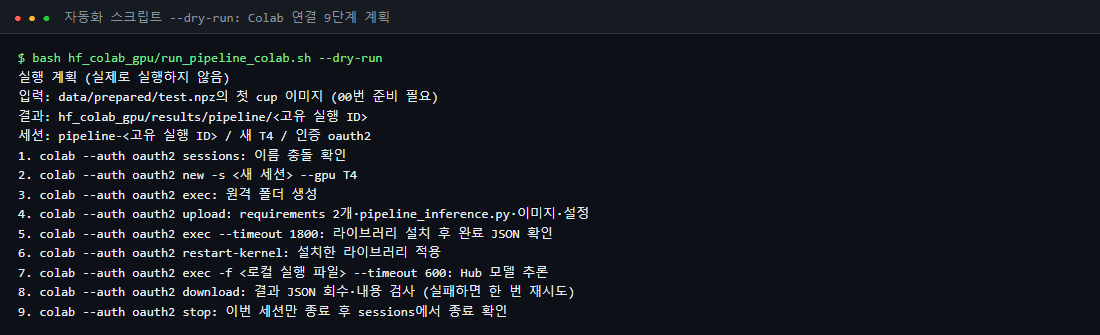

In [9]:
# run_pipeline_colab.sh --dry-run 실행 결과 (이 PC에서 실행)
from IPython.display import Image
Image("images/env_05_dryrun.png")

```bash
bash hf_colab_gpu/run_pipeline_colab.sh --dry-run      # 계획만 확인
colab --auth oauth2 sessions                            # 첫 로그인은 직접
bash hf_colab_gpu/run_pipeline_colab.sh                 # 실제 실행: 새 T4 → 추론 → 회수 → 종료
bash hf_colab_gpu/run_pipeline_colab.sh --image custom_images/my-cup.png
```

### 7-2. 스크립트에서 배울 환경 설계

```bash
set -Eeuo pipefail          # 오류가 나면 즉시 멈춘다
umask 077                   # 새로 만드는 파일을 나만 읽게 한다
CLI=("$COLAB_BIN" --auth "$AUTH")   # 인증 방식을 모든 명령에 똑같이 붙인다

step() {                    # 원격 로그는 화면 대신 비공개 파일에 저장
    local label=$1; shift
    "$@" >"$OUTPUT/logs/$label.log" 2>&1 || { echo "단계 실패: $label"; return 1; }
}
trap cleanup EXIT           # 성공·실패·Ctrl+C 어떤 경우든 마지막에 cleanup 실행
```

| 설계 | 이유 |
|---|---|
| `set -Eeuo pipefail` | 중간 단계가 실패했는데 다음 단계로 넘어가 CU를 낭비하지 않게 |
| `sessions` 스냅숏 전·후 비교 | 이름이 겹치는 세션이 있으면 시작 전에 멈추고, **내가 만든 세션만** 찾아낸다 |
| `trap cleanup EXIT` | 어떤 이유로 끝나든 **이번에 만든 세션만** `stop`하고 목록에서 사라졌는지 확인 |
| 로그를 `logs/`에 저장 | 수업 화면(프로젝터)에 인증 정보가 노출되지 않게 |
| 버전 검사 | 원격에 설치된 버전이 수업 버전과 다르면 실패 처리 |

> "끄는 걸 깜빡해서 요금이 나가는" 위험을 **코드로 막은 것**이다. 6장의 주의점이 그대로 자동화돼 있다.

### 7-3. 에이전트 스킬로 연결

```text
스킬(SKILL.md)  →  셸 파일(.sh)  →  Colab CLI  →  Python pipeline()  →  결과 JSON
```

- 스킬은 AI 코딩 도구가 읽는 **작업 안내서**다. 위치는 `.agents/skills/vision-pipeline-inference/SKILL.md`.
- 에이전트에게 "이 이미지를 Colab에서 추론해 줘"라고 하면 에이전트가 이 셸 파일을 호출한다.
- 터미널 명령과 `--help` 문서만 있으면 UI 없이도 에이전트가 도구를 쓸 수 있다. **CLI가 다시 주목받는 이유**다.
- Colab CLI가 올해 초 나오고 HF CLI도 최근 나온 이유가 **에이전트 통합**이다.

## 8. GPU 고르기와 비용

| 단계 | 추천 | 이유 |
|---|---|---|
| 처음 실험 | **T4** | 가볍고 CU를 적게 쓴다. 이번 실습은 T4로 충분 |
| 모델 키우기 | **L4** | T4보다 메모리가 커서 조금 더 좋은 모델 |
| 본격 실험 | **A100** | 큰 모델, 빠른 학습. CU를 많이 쓴다 |
| 특수 | **TPU** (v5e-1, v6e-1) | 메모리가 매우 크지만 JAX 같은 전용 라이브러리가 필요 |

- H100·G4는 Colab Pro+가 필요하다.
- 전략: **작게 시작(T4) → 모델 키우기(L4) → 큰 GPU(A100)**.
- 추천 순서: **Colab CLI로 안전하게 → 익숙해지면 RunPod → 필요하면 GCP**.

## 9. 환경 트러블슈팅

| 증상 | 원인 | 해결 |
|---|---|---|
| README가 기호투성이 | 마크다운 원본 보기 | `Ctrl+Shift+V` |
| `colab`에서 `termios` 오류 | Windows에서 실행 | Codespaces 또는 WSL에서 실행 |
| `google-colab-cli` 설치 실패 | Python 3.12 미만 | Python 3.12 환경 (`uv venv --python 3.12`) |
| `.venv`가 없음 | 자동 설치 실패 | `bash scripts/setup.sh` |
| `uv`를 찾을 수 없음 | 컨테이너가 옛 설정 | Codespaces: Rebuild Container |
| `ModuleNotFoundError` | 다른 커널 선택 | 커널을 Vision AI (Codespaces CPU)로 |
| 01·02 Run All에서 `torch` 오류 | Codespaces엔 PyTorch 없음 | `colab exec -f`로 Colab에서 실행 |
| `colab login`이 없음 | 0.6.0에 없는 명령 | `colab --auth oauth2 sessions` |
| 로그인 링크가 안 열림 | 터미널 링크 | `Ctrl + 클릭` → 계정 선택 → 코드 붙여넣기 |
| PyTorch 설치가 끊김 | `colab install` 대기시간 짧음 | requirements 업로드 후 `exec --timeout 1800` |
| 설치했는데 import 이상 | 옛 버전이 메모리에 남음 | `colab restart-kernel` |
| `upload` 실패 | 상위 폴더 자동 생성 안 됨 | 먼저 `exec`로 `mkdir` |
| 같은 이름 세션이 있음 | 이전 세션이 안 꺼짐 | `colab sessions` 확인 후 `stop` 또는 새 이름 |
| 명령은 끝났는데 결과가 이상 | 셀 오류 후에도 계속 실행됨 | `*_output.ipynb`에서 오류 확인 |

## 10. 복습 체크리스트

> 🗣️ 강사님: "코드 한 줄 한 줄보다 **어떤 흐름으로 무슨 일을 하는지**가 머릿속에 들어가야 한다. 흐름을 말이나 글로 정리해 봐야 한다."

- [ ] 환경 3층(Codespaces, 인증, Colab 런타임)을 그림 없이 설명할 수 있다
- [ ] `devcontainer.json` → `Dockerfile` → `setup.sh` → `.venv` 순서를 안다
- [ ] Colab CLI가 Python 3.12와 리눅스·맥이 필요하다는 것을 안다
- [ ] `doctor.py`로 환경을 점검하고 결과를 읽을 수 있다
- [ ] `colab --auth oauth2 sessions`로 로그인할 수 있다
- [ ] PyTorch가 Codespaces가 아니라 Colab에 설치되는 이유를 안다
- [ ] `new → upload → exec → restart-kernel → exec -f → download → stop → sessions` 순서를 안다
- [ ] `content/...`와 `/content/...`의 차이를 안다
- [ ] `--timeout`이 초 단위이고 자동 종료가 아님을 안다
- [ ] 실습 후 **Colab 세션 종료 + Codespace 중지**를 했다 ⭐

## 부록 A. 실습 코드 흐름 요약

환경이 준비되면 실습 노트북 3개를 이 순서로 돌린다. 모델 자체는 연결을 확인하는 예제다.

| 노트북 | 실행 위치 | 하는 일 |
|---|---|---|
| 00 · HF CLI와 데이터 준비 | Codespaces CPU | `hf download`로 모델 3개 파일 받기, SHA-256 확인, 데이터 분할 |
| 01 · GPU 추론 | Colab GPU (`exec -f`) | `pipeline()`으로 원본 모델 추론, Top-5 |
| 02 · GPU 파인튜닝 | Colab GPU (`exec -f`) | 분류기 학습 → 마지막 블록 파인튜닝 → 저장·재로딩 |

```bash
hf download facebook/deit-tiny-patch16-224 config.json preprocessor_config.json pytorch_model.bin \
  --revision b3428f18dcc7b543470d07f14b4a4157815d1880 \
  --local-dir hf_colab_gpu/models/deit-tiny
```

- `--revision`은 모델의 **지문(커밋 SHA)** 이다. 고정하면 모두가 같은 파일로 실험한다. 클로즈드 모델처럼 몰래 바뀌는 일이 없다.
- 받는 파일 3개: `config.json`(설정), `preprocessor_config.json`(전처리), `pytorch_model.bin`(가중치, 약 23MB).
- `hf download`는 파일을 받는 것까지다. 파일을 Python 모델로 읽는 건 Colab에서 `from_pretrained(..., local_files_only=True)`가 한다.

```python
image_classifier = pipeline(
    "image-classification",      # 무슨 작업? → 이미지 분류
    model=model,                 # 업로드한 DeiT
    image_processor=processor,   # 업로드한 전처리 설정
    framework="pt",              # PyTorch
    device=device,               # Colab GPU
)
predictions = image_classifier(image, top_k=5)
```

## 부록 B. 모델 실행 결과 (CPU 재현)

같은 코드를 내 PC의 CPU에서 장치만 바꿔 실행해 봤다 (`code/run_cpu_demo.py`, 약 2분). DeiT-tiny는 작아서 CPU로도 되지만, 더 큰 모델을 쓰려면 결국 GPU 연결이 필요하다.

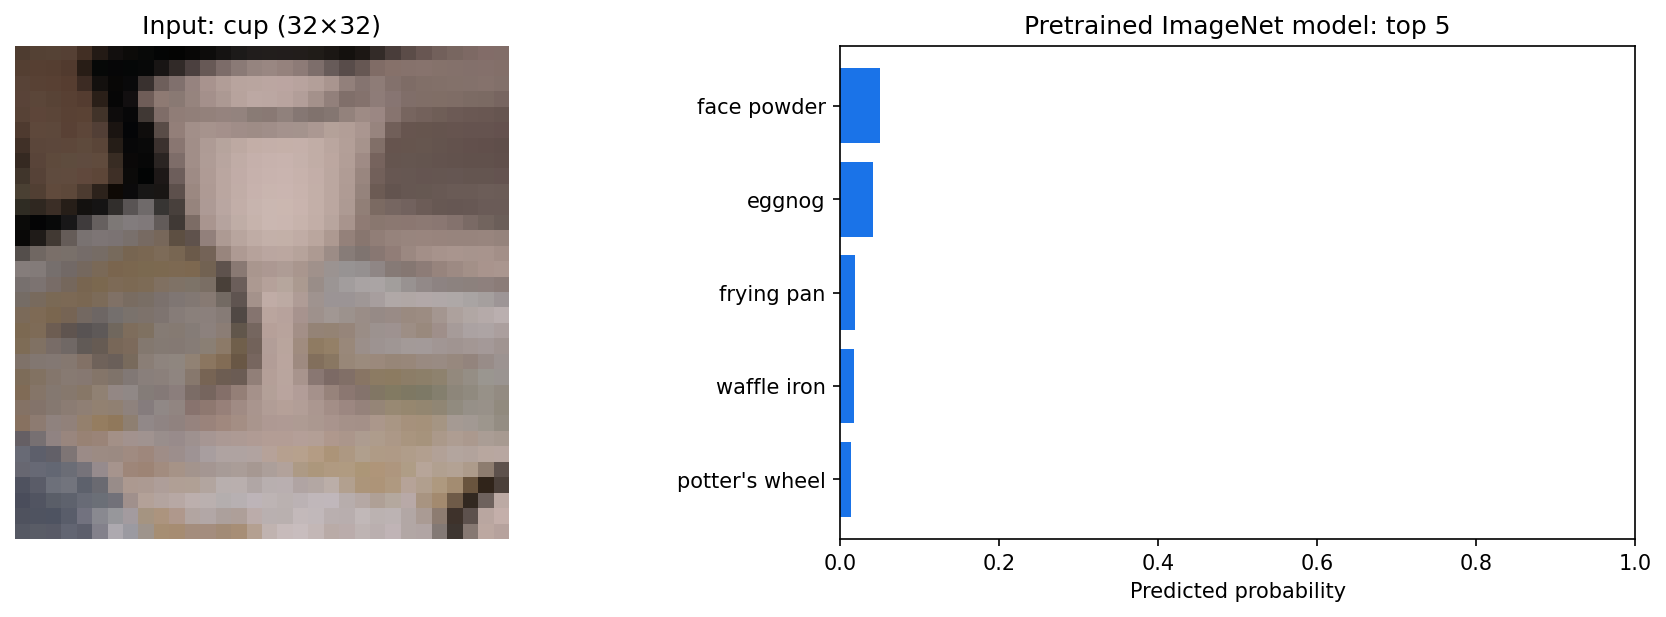

In [10]:
# 원본 모델은 컵을 face powder로 예측 (ImageNet 1,000 라벨)
from IPython.display import Image
Image("images/02_pretrained_top5.png")

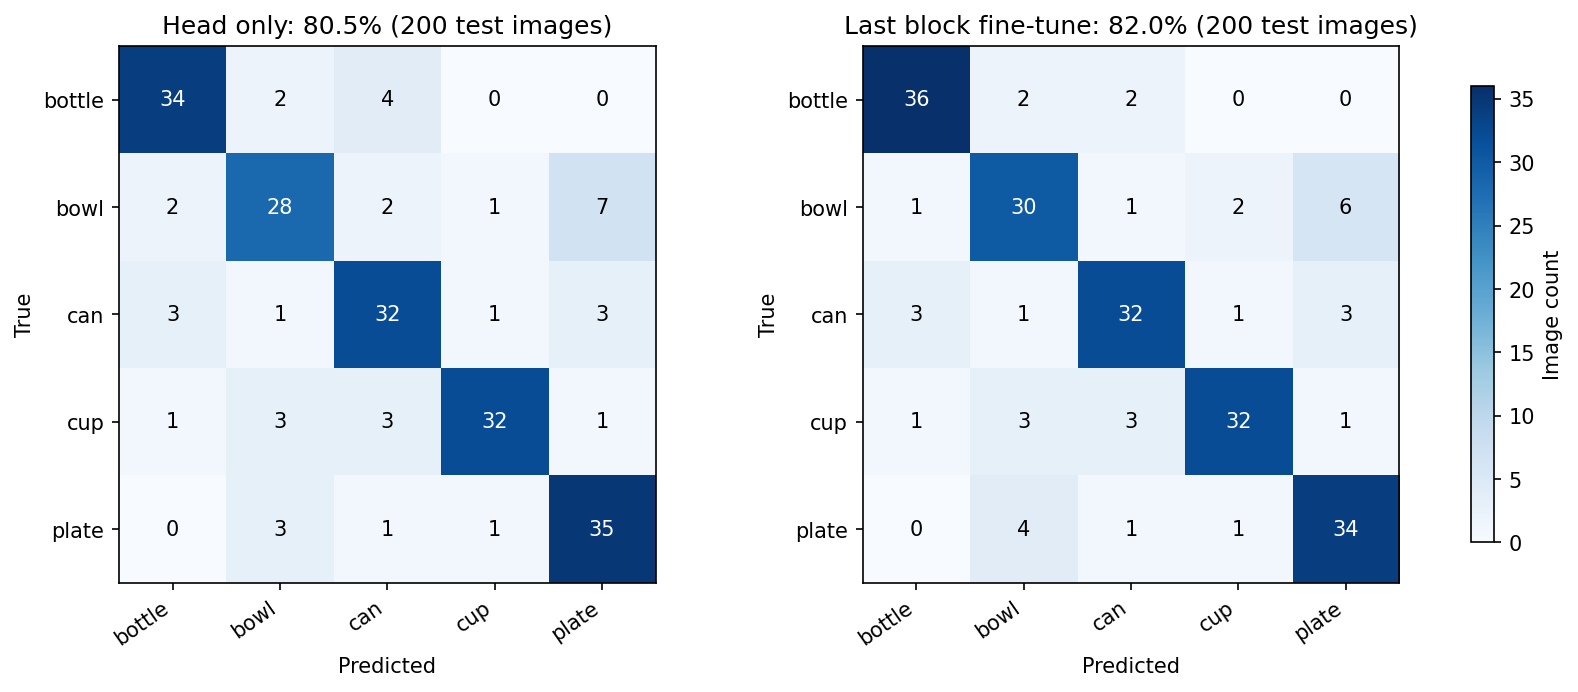

In [11]:
# 5개 클래스로 파인튜닝한 뒤 테스트 200장 혼동행렬
from IPython.display import Image
Image("images/04_confusion_comparison.png")

| 비교 | 내 CPU 재현 | 원본 저장소 T4 기록 (2026-09-19) |
|---|---|---|
| 분류기만 학습 | 80.5% | 80.0% |
| 마지막 블록까지 파인튜닝 | 82.0% | 81.0% |